# 02 - Clean and split

This notebook rebuilds the data from the raw files with one function, `build_dataset()` in `src/clean.py`, and shows every decision behind it:

1. What the raw files look like
2. The **findings table**: each problem, how many rows have it, and whether we **fix, flag or drop**
3. The cleaning function, step by step, with the positive rate after each step
4. The three groups every team must decide on: flex fare trips, trips that cannot be real, non-standard fares
5. The split: May train, June validation, July test
6. The analysis for Team C (the crawl): by hour and weekday, a zone map, which trips crawl, stability over the months
7. Does the kind of split matter?

**Rule for this notebook:** every analysis is done on **May (training) only**, so no choice is made by looking at June or July. The one exception is section 6.4, which reports the crawl rate by month: that is the stability check the brief asks for, and nothing is tuned on it.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.patches import Patch
from src.clean import *
from src.models import BusyRule, make_tree
from src.evaluate import metrics
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 90)
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)

# one look for every figure: thin marks, recessive grid, fixed colour order
BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#c9c8c2", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "lines.linewidth": 2})
pct = lambda x: f"{100 * x:.1f}%"

## 1. The raw files
One row per trip, 21 columns, exactly as the TLC published them. The table shows each column's type, how much is missing, and its range, which is where most of the problems below first show up.

In [2]:
trips_raw, zones = load_raw()
print(f"{len(trips_raw):,} trips, {trips_raw.shape[1]} columns; {len(zones)} zones in the lookup")

def describe_raw(t):
    rows = []
    for c in t.columns:
        s = t[c]
        num = pd.api.types.is_numeric_dtype(s) or pd.api.types.is_datetime64_any_dtype(s)
        rows.append({"column": c, "dtype": str(s.dtype), "missing_%": round(100 * s.isna().mean(), 2),
                     "unique": s.nunique(), "min": s.min() if num else "", "max": s.max() if num else ""})
    return pd.DataFrame(rows).set_index("column")
describe_raw(trips_raw)

600,000 trips, 21 columns; 265 zones in the lookup


,dtype,missing_%,unique,min,max
column,,,,,
VendorID,int32,0.00,4,1,7
tpep_pickup_datetime,datetime64[us],0.00,571549,2026-04-18 21:51:07,2026-07-31 23:59:58
tpep_dropoff_datetime,datetime64[us],0.00,571739,2026-04-18 22:09:09,2026-08-01 20:13:25
passenger_count,float64,25.75,7,0.0,6.0
trip_distance,float64,0.00,3423,0.0,317017.94
RatecodeID,float64,25.75,6,1.0,99.0
store_and_fwd_flag,str,25.75,2,,
PULocationID,int32,0.00,251,1,265
DOLocationID,int32,0.00,259,1,265


In [3]:
codes = pd.concat({
    "payment_type": trips_raw.payment_type.value_counts(dropna=False).sort_index(),
    "RatecodeID": trips_raw.RatecodeID.value_counts(dropna=False).sort_index(),
}, axis=1)
codes.index.name = "code"
codes

,payment_type,RatecodeID
code,,
0.0,154475.0,NaN
1.0,383942.0,412451.0
2.0,56414.0,14264.0
3.0,1723.0,1844.0
4.0,3446.0,1361.0
5.0,NaN,5646.0
99.0,NaN,9959.0
NaN,NaN,154475.0


**What to look for.** Pickup dates outside May to July; drop-off times before pickup; zero and huge distances; negative money; `passenger_count` and `RatecodeID` missing together (the flex trips, `payment_type` 0); `RatecodeID` 99 (unknown); zones 264 and 265 (unknown / outside NYC). Codes are from `data_dictionary_trip_records_yellow.pdf`:
payment 0 flex fare, 1 card, 2 cash, 3 no charge, 4 dispute, 5 unknown, 6 voided; rate 1 standard, 2 JFK, 3 Newark, 4 Nassau/Westchester, 5 negotiated, 6 group, 99 unknown.

## 2. The findings table
Each problem is counted **on the raw rows, independently** (one trip can have several problems, so the rows do not add up). The decision rule:

* **drop** when the trip cannot be labelled (speed undefined or meaningless) or is not a real trip;
* **flag** when the trip is real but special: kept, marked with a column, used to slice results later, and never a feature;
* **fix** when a value is a code for "missing" and would otherwise be read as a number.

In [4]:
audit = audit_raw(trips_raw)
audit

,problem,rows,share_%,decision,why
0,pickup outside May to July 2026,2,0.000,drop,belongs to no split; the split is by pickup month
1,exact duplicate row,0,0.000,drop,the same trip counted twice would weigh double
2,drop-off not after pickup (duration <= 0),7676,1.279,drop,speed undefined: no label possible
3,zero distance,19500,3.250,drop,speed 0 would fake a crawl; usually a cancelled or voided ride
4,duration under 1 min,6407,1.068,drop,speed is rounding noise
5,duration over 180 min,180,0.030,drop,meter left running; not a real duration
6,distance under 0.1 mi (but > 0),4709,0.785,drop,not a real trip; speed meaningless
7,speed over 80 mph,158,0.026,drop,impossible in New York: distance or clock error
8,unknown zone (264/265) at pickup or drop-off,4248,0.708,drop,"no place to learn from, cannot be mapped, and the warning needs a known zone"
9,negative amount in any money column,2298,0.383,drop,"reversals / corrections, not real trips"


In [5]:
audit.groupby("decision").problem.count().rename("problems")

decision
drop    11
fix      2
flag     7
Name: problems, dtype: int64

## 3. The cleaning function
`build_dataset()` reads the raw files and applies the **drop** rows of the findings table **in the order shown**, then the fixes and flags, then builds the target, adds the zone names (with a row-count check) and the split. The log below gives the rows removed by each step, which is smaller than the raw count above when an earlier step already removed the row.

In [6]:
df, log = build_dataset()
show = log.copy(); show["positive_rate"] = (100 * show.positive_rate).round(2)
display(show)
print(f"kept {len(df):,} of {len(trips_raw):,} trips ({100 * len(df) / len(trips_raw):.1f}%); "
      f"positive rate {pct(df.crawl.mean())} over the three months")

,step,removed,rows_left,positive_rate
0,raw file,0,600000,NaN
1,drop: pickup outside May to July 2026,2,599998,17.74
2,drop: exact duplicate row,0,599998,17.74
3,drop: drop-off not after pickup (duration <= 0),7676,592322,17.97
4,drop: zero distance,19309,573013,18.57
5,drop: duration under 1 min,1919,571094,18.53
6,drop: duration over 180 min,175,570919,18.51
7,drop: distance under 0.1 mi (but > 0),3265,567654,18.04
8,drop: speed over 80 mph,104,567550,18.04
9,drop: unknown zone (264/265) at pickup or drop-off,3781,563769,18.13


kept 559,438 of 600,000 trips (93.2%); positive rate 18.1% over the three months


**Checks.** The function must give the same table every time it runs from the raw files, and the kept rows must satisfy every rule.

In [7]:
df_again, _ = build_dataset()
pd.testing.assert_frame_equal(df, df_again)          # rebuilds identically
assert df.duration_min.between(MIN_DURATION_MIN, MAX_DURATION_MIN).all()
assert (df.trip_distance >= MIN_DISTANCE_MI).all() and (df.speed_mph <= MAX_SPEED_MPH).all()
assert not df.PULocationID.isin(UNKNOWN_ZONES).any() and not df.DOLocationID.isin(UNKNOWN_ZONES).any()
assert not df.payment_type.isin([NO_CHARGE, DISPUTE, VOIDED]).any()
assert (df[amount_columns(df)].fillna(0) >= 0).all().all()      # blanks are allowed, negatives are not
assert df.crawl.equals((df.speed_mph < CRAWL_MPH).astype("int8"))
assert df.pickup_zone.notna().all() and df.dropoff_zone.notna().all()
assert not df.duplicated(subset=list(trips_raw.columns)).any()
print("all checks pass")
del df_again

all checks pass


## 4. The three groups every team must decide on
Shown on **May only**. These flags are settled at the end of the trip, so none of them can be a feature. The question is only whether to keep the trips.

In [8]:
may = df[df.split == "train"]
def rate_by(col, data=may):
    g = data.groupby(col, dropna=False).crawl.agg(trips="size", crawl_rate="mean")
    g["share_of_trips_%"] = (100 * g.trips / g.trips.sum()).round(1)
    g["crawl_rate"] = (100 * g.crawl_rate).round(1)
    return g
display(rate_by("is_flex").rename(index={0: "metered (card, cash...)", 1: "flex fare (payment 0)"}))
display(rate_by("RatecodeID"))

,trips,crawl_rate,share_of_trips_%
is_flex,,,
"metered (card, cash...)",145773,21.8,77.7
flex fare (payment 0),41921,10.9,22.3


,trips,crawl_rate,share_of_trips_%
RatecodeID,,,
1.0,133419,22.8,71.1
2.0,4253,0.4,2.3
3.0,518,3.1,0.3
4.0,56,0.0,0.0
5.0,693,4.5,0.4
NaN,48755,11.9,26.0


| Group | Decision | Why |
|---|---|---|
| **Flex fare trips** (payment 0, no passenger count, no rate code) | **Keep, flag `is_flex`** | They are about a quarter of real trips and they do have a valid pickup, drop-off, distance and duration, so the target is well defined. Dropping them would train the model on a different mix of trips from the one it will see. The missing columns are ones we never use. Flex is reported as a slice in notebook 04. |
| **Trips that cannot be real**: zero distance, impossible durations or speeds, negative amounts, voided / no-charge / disputed, unknown zones | **Drop** | No meaningful speed, or not a trip that happened as recorded. Unknown zones also cannot be learned from or mapped. |
| **Non-standard fares** (rate 2 to 6, and 99) | **Keep, flag `nonstandard_rate`**, recode 99 to missing | Airport flat fares and negotiated rides are real trips, and the dispatcher must warn those passengers too. The rate code is set at the end, so it is never a feature. |

## 5. The split
By pickup time, the same for every team: **May trains, June validates every choice, July is the final test, scored once in notebook 04.** The model will be used on future trips, so it must be judged on months it has not seen.

In [9]:
split_tab = (df.groupby("split")
               .agg(first_pickup=("tpep_pickup_datetime", "min"), last_pickup=("tpep_pickup_datetime", "max"),
                    trips=("crawl", "size"), positive_rate=("crawl", "mean"))
               .loc[["train", "validation", "test"]])
split_tab["positive_rate"] = (100 * split_tab.positive_rate).round(2)
assert split_tab.last_pickup.iloc[0] < split_tab.first_pickup.iloc[1] < split_tab.last_pickup.iloc[1] < split_tab.first_pickup.iloc[2]
split_tab

,first_pickup,last_pickup,trips,positive_rate
split,,,,
train,2026-05-01 00:00:28,2026-05-31 23:59:14,187694,19.34
validation,2026-06-01 00:00:08,2026-06-30 23:59:57,186184,18.54
test,2026-07-01 00:00:44,2026-07-31 23:59:58,185560,16.32


## 6. The analysis: which trips crawl?
### 6.1 Overall, by hour of the day and by day of the week (May)
19.3% of May trips crawl. On weekdays the rate climbs from under 1% at 4am to about 38% around noon and stays high through the afternoon; weekends are much lower (Sunday 9%, Thursday 25%).

May: 187,694 trips, positive rate 19.3%


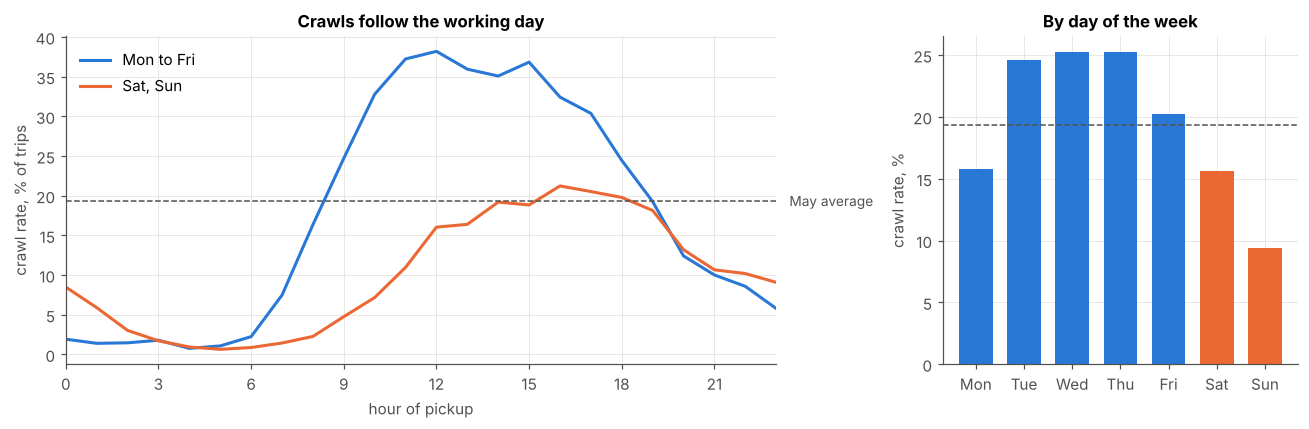

weekday peak at 12h (38.2%), weekday low at 4h (0.8%); busiest-crawl day Thu (25.2%), lowest Sun (9.4%)


In [10]:
base = may.crawl.mean()
print(f"May: {len(may):,} trips, positive rate {pct(base)}")
h = may.assign(hour=may.tpep_pickup_datetime.dt.hour, wd=may.tpep_pickup_datetime.dt.dayofweek)
by_hour = h.groupby([h.wd >= 5, "hour"]).crawl.mean().unstack(0).rename(columns={False: "weekday", True: "weekend"})
by_wd = h.groupby("wd").crawl.agg(["mean", "size"]); by_wd.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [2, 1]})
ax[0].plot(by_hour.index, 100 * by_hour.weekday, color=BLUE, label="Mon to Fri")
ax[0].plot(by_hour.index, 100 * by_hour.weekend, color=ORANGE, label="Sat, Sun")
ax[0].axhline(100 * base, color=INK, lw=1, ls="--"); ax[0].text(23.3, 100 * base, " May average", va="center", color=INK, fontsize=9)
ax[0].set(xlabel="hour of pickup", ylabel="crawl rate, % of trips", xticks=range(0, 24, 3), xlim=(0, 23))
ax[0].set_title("Crawls follow the working day"); ax[0].legend(frameon=False, loc="upper left")
ax[1].bar(by_wd.index, 100 * by_wd["mean"], color=[BLUE] * 5 + [ORANGE] * 2, width=0.7)
ax[1].axhline(100 * base, color=INK, lw=1, ls="--")
ax[1].set(ylabel="crawl rate, %"); ax[1].set_title("By day of the week")
fig.tight_layout(); fig.savefig(FIG / "02_rate_by_hour_weekday.png", bbox_inches="tight"); plt.show()

peak = by_hour.weekday.idxmax(); low = by_hour.weekday.idxmin()
print(f"weekday peak at {peak}h ({pct(by_hour.weekday.max())}), weekday low at {low}h ({pct(by_hour.weekday.min())}); "
      f"busiest-crawl day {by_wd['mean'].idxmax()} ({pct(by_wd['mean'].max())}), lowest {by_wd['mean'].idxmin()} ({pct(by_wd['mean'].min())})")

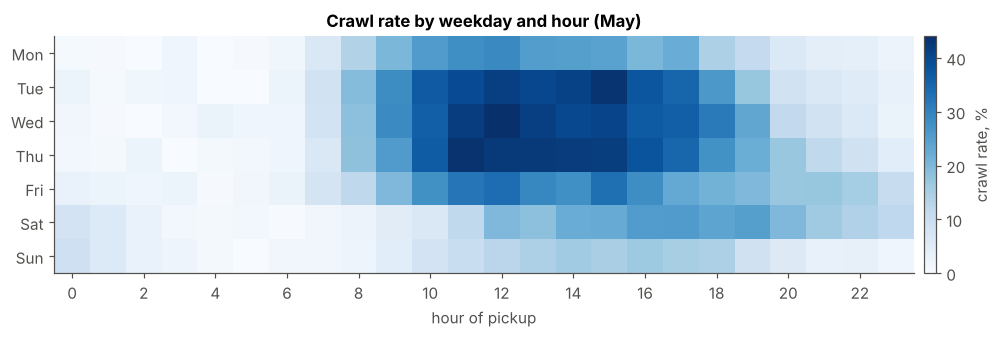

In [11]:
heat = h.pivot_table(index="wd", columns="hour", values="crawl", aggfunc="mean")
fig, ax = plt.subplots(figsize=(12, 2.8))
im = ax.imshow(100 * heat.values, aspect="auto", cmap="Blues")
ax.set(yticks=range(7), yticklabels=by_wd.index, xticks=range(0, 24, 2), xlabel="hour of pickup"); ax.grid(False)
ax.set_title("Crawl rate by weekday and hour (May)")
fig.colorbar(im, ax=ax, label="crawl rate, %", pad=0.01)
fig.savefig(FIG / "02_rate_heatmap.png", bbox_inches="tight"); plt.show()

### 6.2 By pickup zone: the map
Crawl rate of May pickups in each zone. Zones with fewer than 30 May pickups are grey, because a rate on so few trips is noise. The shapefile's coordinates are in feet (New York State Plane), so the scale bar is drawn in feet.

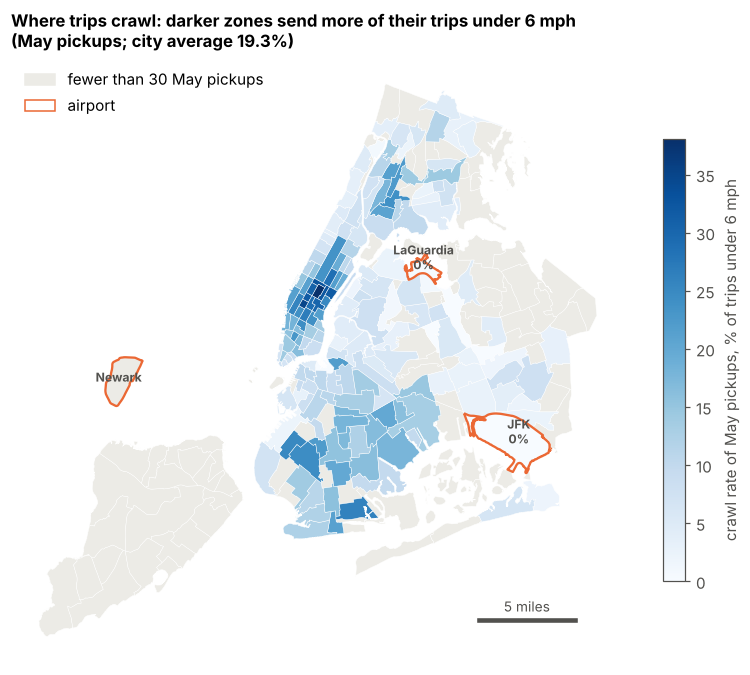

In [12]:
MIN_TRIPS = 30
zstats = may.groupby("PULocationID").crawl.agg(trips="size", crawl_rate="mean").reset_index()
shapes = load_zone_shapes()
gz = shapes.merge(zstats, left_on="LocationID", right_on="PULocationID", how="left")
enough = gz.trips >= MIN_TRIPS

fig, ax = plt.subplots(figsize=(9, 9.5))
if (~enough).any(): gz[~enough].plot(ax=ax, color="#ecebe6", edgecolor="white", linewidth=0.3)
gz[enough].plot(ax=ax, column=gz.loc[enough, "crawl_rate"] * 100, cmap="Blues", edgecolor="white", linewidth=0.3,
                legend=True, legend_kwds={"label": "crawl rate of May pickups, % of trips under 6 mph", "shrink": 0.55})
air = gz[gz.LocationID.isin(AIRPORT_ZONES)]
air.boundary.plot(ax=ax, color=ORANGE, linewidth=1.5)
for _, r in air.iterrows():
    p = r.geometry.representative_point()
    lab = {1: "Newark", 132: "JFK", 138: "LaGuardia"}[r.LocationID]
    rate = "" if pd.isna(r.crawl_rate) else f"\n{100 * r.crawl_rate:.0f}%"
    ax.annotate(lab + rate, (p.x, p.y), fontsize=8, color=INK, ha="center", fontweight="bold")
x0, y0, x1, y1 = gz.total_bounds; L = 5 * 5280
xs = x1 - 0.04 * (x1 - x0) - L                       # scale bar, bottom right (open water on the real map)
ax.plot([xs, xs + L], [y0 + 0.03 * (y1 - y0)] * 2, color=INK, lw=3)
ax.text(xs + L / 2, y0 + 0.045 * (y1 - y0), "5 miles", ha="center", color=INK, fontsize=9)
ax.legend(handles=[Patch(color="#ecebe6", label=f"fewer than {MIN_TRIPS} May pickups"),
                   Patch(facecolor="none", edgecolor=ORANGE, label="airport")], loc="upper left", frameon=False)
ax.set_axis_off()
ax.set_title(f"Where trips crawl: darker zones send more of their trips under 6 mph\n"
             f"(May pickups; city average {pct(base)})", loc="left")
fig.savefig(FIG / "02_crawl_map.png", bbox_inches="tight", dpi=150); plt.show()

In [13]:
top = (zstats[zstats.trips >= 500].merge(zones, left_on="PULocationID", right_on="LocationID")
       .sort_values("crawl_rate", ascending=False))
top["crawl_rate"] = (100 * top.crawl_rate).round(1)
cols = ["PULocationID", "Zone", "Borough", "trips", "crawl_rate"]
print("Highest crawl rate, zones with 500+ May pickups"); display(top[cols].head(10))
print("Lowest"); display(top[cols].tail(5))
share_from = may.groupby("pickup_borough").crawl.agg(trips="size", crawl_rate="mean")
share_from["crawl_rate"] = (100 * share_from.crawl_rate).round(1); share_from.sort_values("trips", ascending=False)

Highest crawl rate, zones with 500+ May pickups


,PULocationID,Zone,Borough,trips,crawl_rate
31,161,Midtown Center,Manhattan,7646,38.1
37,186,Penn Station/Madison Sq West,Manhattan,5306,35.0
33,163,Midtown North,Manhattan,4554,32.8
32,162,Midtown East,Manhattan,5622,32.6
39,229,Sutton Place/Turtle Bay North,Manhattan,3034,31.7
15,100,Garment District,Manhattan,2330,31.7
40,230,Times Sq/Theatre District,Manhattan,5150,30.7
36,170,Murray Hill,Manhattan,4797,30.3
34,164,Midtown South,Manhattan,3441,29.0
46,237,Upper East Side South,Manhattan,9388,28.7


Lowest


,PULocationID,Zone,Borough,trips,crawl_rate
35,166,Morningside Heights,Manhattan,1346,4.1
2,24,Bloomingdale,Manhattan,611,3.4
51,255,Williamsburg (North Side),Brooklyn,507,3.0
22,138,LaGuardia Airport,Queens,4921,0.4
20,132,JFK Airport,Queens,6426,0.1


,trips,crawl_rate
pickup_borough,,
Manhattan,163219,21.5
Queens,15466,1.3
Brooklyn,7283,10.8
Bronx,1716,9.9
Staten Island,10,0.0


### 6.3 Which trips crawl: short or long, within Manhattan or across boroughs, to or from airports?
Distance here is the **measured** distance, used only to describe the data. It is not a feature: the model gets an estimated planned distance instead (notebook 03).

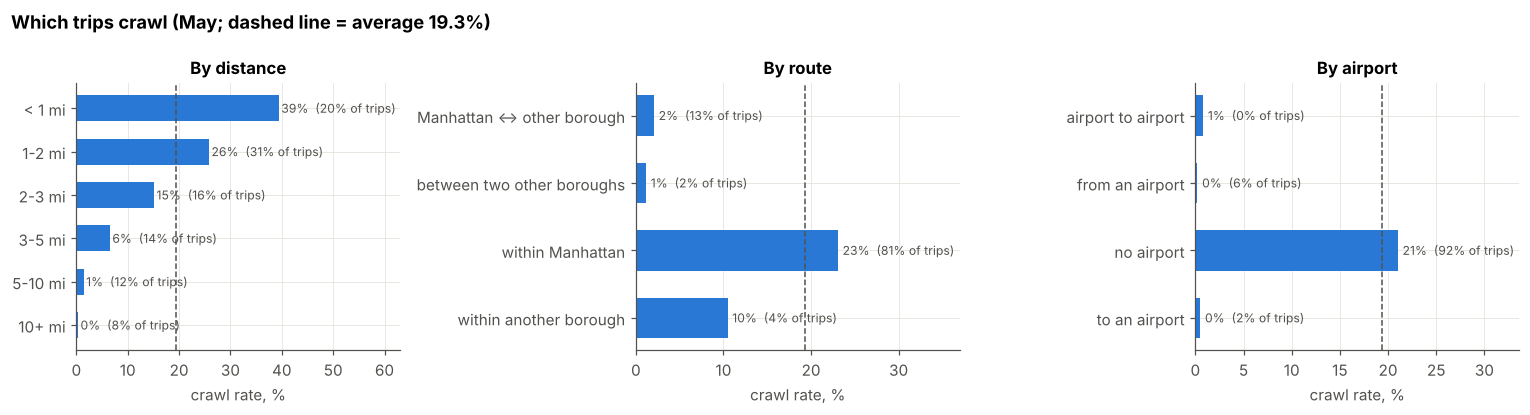

,trips,crawl_rate,share_of_trips_%
distance,,,
< 1 mi,37726,39.4,20.1
1-2 mi,57510,25.8,30.6
2-3 mi,30101,15.1,16.0
3-5 mi,25593,6.5,13.6
5-10 mi,22663,1.4,12.1
10+ mi,14101,0.3,7.5


,trips,crawl_rate,share_of_trips_%
route,,,
Manhattan <-> other borough,23966,2.1,12.8
between two other boroughs,4480,1.2,2.4
within Manhattan,151350,23.1,80.6
within another borough,7898,10.5,4.2


,trips,crawl_rate,share_of_trips_%
airport,,,
airport to airport,240,0.8,0.1
from an airport,11107,0.2,5.9
no airport,173031,21.0,92.2
to an airport,3316,0.5,1.8


In [14]:
m = may.copy()
m["distance"] = pd.cut(m.trip_distance, [0, 1, 2, 3, 5, 10, np.inf],
                       labels=["< 1 mi", "1-2 mi", "2-3 mi", "3-5 mi", "5-10 mi", "10+ mi"], right=False)
pm, dm = m.pickup_borough == "Manhattan", m.dropoff_borough == "Manhattan"
m["route"] = np.select([pm & dm, pm ^ dm, m.pickup_borough == m.dropoff_borough],
                       ["within Manhattan", "Manhattan <-> other borough", "within another borough"],
                       "between two other boroughs")
pa, da = m.PULocationID.isin(AIRPORT_ZONES), m.DOLocationID.isin(AIRPORT_ZONES)
m["airport"] = np.select([pa & da, pa, da], ["airport to airport", "from an airport", "to an airport"], "no airport")

tabs = {c: rate_by(c, m) for c in ["distance", "route", "airport"]}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (c, t) in zip(axes, tabs.items()):
    t = t[t.trips >= 30]
    ax.barh(t.index.astype(str), t.crawl_rate, color=BLUE, height=0.6)
    ax.axvline(100 * base, color=INK, lw=1, ls="--")
    for i, (r, s) in enumerate(zip(t.crawl_rate, t["share_of_trips_%"])):
        ax.text(r + 0.5, i, f"{r:.0f}%  ({s:.0f}% of trips)", va="center", fontsize=8, color=INK)
    ax.invert_yaxis(); ax.set_xlabel("crawl rate, %"); ax.set_title(f"By {c}")
    ax.set_xlim(0, max(t.crawl_rate) * 1.6)
fig.suptitle(f"Which trips crawl (May; dashed line = average {pct(base)})", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "02_crawl_by_trip_type.png", bbox_inches="tight"); plt.show()
for c, t in tabs.items(): display(t)

In [15]:
# short trips inside Manhattan on weekday daytime: the obvious candidate for a warning
busy = (m.tpep_pickup_datetime.dt.dayofweek < 5) & m.tpep_pickup_datetime.dt.hour.between(8, 19)
cross = pd.crosstab([m.route], [busy.rename("weekday 8-19h")], values=m.crawl, aggfunc="mean").mul(100).round(1)
cross

weekday 8-19h,False,True
route,,
Manhattan <-> other borough,0.9,3.9
between two other boroughs,0.6,2.0
within Manhattan,12.8,35.3
within another borough,4.8,19.6


**Reading it (May).**
* **Short or long?** Distance is the strongest pattern: about 39% of trips under 1 mile crawl, 15% at 2-3 miles, under 2% beyond 5 miles. A short ride has a fixed cost (lights, pick-up, drop-off) that pulls its average speed down. This is why the planned distance is worth estimating.
* **Within Manhattan or across boroughs?** Trips inside Manhattan crawl about 23% of the time (35% on weekdays 8-19h); trips between Manhattan and another borough about 2%, because they use highways and bridges. Midtown (Midtown Center, Penn Station, Midtown North and East, Times Square) is the core of the problem, as the map shows.
* **Airports?** Almost never: under 1% of trips to or from JFK, LaGuardia or Newark crawl. They are long and mostly on highways.

### 6.4 Is the positive rate stable from May to June to July?
This is the only place labels of June and July are looked at in this notebook, and only as rates. Nothing is tuned on them.

,trips,crawl_rate,flex_share,app_booked_share,median_distance,median_minutes
month,,,,,,
May (train),187694,19.34,22.33,0.00,1.95,14.68
June (validation),186184,18.54,25.22,25.21,1.91,14.25
July (test),185560,16.32,26.11,26.10,2.00,14.28


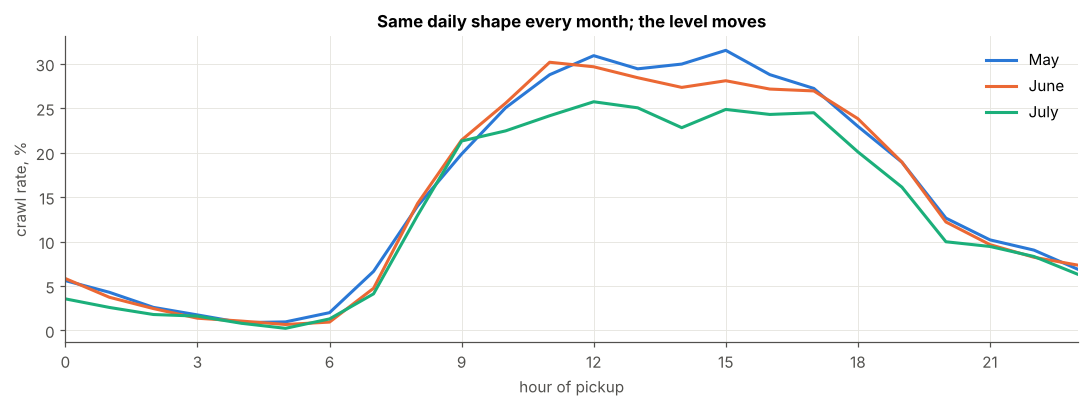

crawl rate May 19.3%, June 18.5%, July 16.3%: change May to July -3.0 points

crawl rate by whether request_source is filled (it is empty for all of May):


,size (empty),size (request_source filled),mean (empty),mean (request_source filled)
month,,,,
5,187694.0,NaN,0.193,NaN
6,139245.0,46939.0,0.213,0.102
7,137122.0,48438.0,0.191,0.084


In [16]:
stab = (df.assign(app_booked=df.request_source.notna() if "request_source" in df else False)
          .groupby("month").agg(trips=("crawl", "size"), crawl_rate=("crawl", "mean"), flex_share=("is_flex", "mean"),
                                app_booked_share=("app_booked", "mean"),
                                median_distance=("trip_distance", "median"), median_minutes=("duration_min", "median")))
stab.index = stab.index.map({5: "May (train)", 6: "June (validation)", 7: "July (test)"})
for c in ["crawl_rate", "flex_share", "app_booked_share"]: stab[c] = (100 * stab[c]).round(2)
display(stab.round(2))

hm = df.assign(hour=df.tpep_pickup_datetime.dt.hour).groupby(["month", "hour"]).crawl.mean().unstack(0)
fig, ax = plt.subplots(figsize=(10, 3.8))
for mo, col, lab in [(5, BLUE, "May"), (6, ORANGE, "June"), (7, AQUA, "July")]:
    ax.plot(hm.index, 100 * hm[mo], color=col, label=lab)
ax.set(xlabel="hour of pickup", ylabel="crawl rate, %", xticks=range(0, 24, 3), xlim=(0, 23))
ax.set_title("Same daily shape every month; the level moves"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "02_stability.png", bbox_inches="tight"); plt.show()
r = df.groupby("month").crawl.mean()
print(f"crawl rate May {pct(r[5])}, June {pct(r[6])}, July {pct(r[7])}: change May to July {100 * (r[7] - r[5]):+.1f} points")
if "request_source" in df:
    rs = df.groupby([df.month, df.request_source.notna().map({True: "request_source filled", False: "empty"})]).crawl.agg(["size", "mean"]).unstack()
    rs.columns = [f"{a} ({b})" for a, b in rs.columns]
    print("\ncrawl rate by whether request_source is filled (it is empty for all of May):"); display(rs.round(3))

**Why it matters.** If the rate drifts, a model trained on May will be calibrated to May: precision at a fixed threshold changes, and the threshold chosen on June may not be the best one in July. One cause is visible in the data: from June, a column `request_source` appears, filled only for flex trips (codes such as `HV0003`, the app booking licence), and those trips crawl much less than the rest. May has none of them, so the trip mix the model was trained on is not the mix it is used on. That is why notebook 04 reports **PR AUC lift** (PR AUC divided by the month's positive rate) next to PR AUC, and why the model card recommends re-checking the threshold every month. Summer traffic (school holidays, fewer commuters in July) may add to it.

## 7. Does the kind of split matter?
A random split mixes May and June trips in both halves, so the model is tested on days it has already seen. We compare the two baselines that learn (the dispatcher rule and the depth-2 tree) on a **random 80/20 split of May+June** and on the **time split** (May train, June validation). July is not used. The tree uses simple time and zone flags here; the full features come in notebook 03.

In [17]:
def simple_feats(d):
    t = d.tpep_pickup_datetime
    return pd.DataFrame({"hour": t.dt.hour, "weekday": t.dt.dayofweek,
                         "is_rush": ((t.dt.dayofweek < 5) & t.dt.hour.between(8, 19)).astype(int),
                         "pu_manhattan": (d.pickup_borough == "Manhattan").astype(int),
                         "do_manhattan": (d.dropoff_borough == "Manhattan").astype(int),
                         "cross_borough": (d.pickup_borough != d.dropoff_borough).astype(int),
                         "airport": (d.PULocationID.isin(AIRPORT_ZONES) | d.DOLocationID.isin(AIRPORT_ZONES)).astype(int)})

def score_split(tr, te):
    rule = BusyRule().fit(tr)
    tree = make_tree(2).fit(simple_feats(tr), tr.crawl)
    return {"busy-hours rule": metrics(te.crawl, rule.predict_proba(te)[:, 1])["pr_auc"],
            "depth-2 tree": metrics(te.crawl, tree.predict_proba(simple_feats(te))[:, 1])["pr_auc"],
            "positive rate of test part": te.crawl.mean()}

may_june = df[df.split.isin(["train", "validation"])]
rnd = may_june.sample(frac=1, random_state=0); cut = int(0.8 * len(rnd))
cmp = pd.DataFrame({"random 80/20 of May+June": score_split(rnd.iloc[:cut], rnd.iloc[cut:]),
                    "time: May -> June": score_split(may, df[df.split == "validation"])}).T.round(3)
cmp

,busy-hours rule,depth-2 tree,positive rate of test part
random 80/20 of May+June,0.252,0.303,0.190
time: May -> June,0.244,0.292,0.185


**Reading it.** The two rows are close (depth-2 tree 0.303 on the random split, 0.292 on the time split), so May and June are similar enough that a random split would only flatter the baselines a little. The real shift is in July, where the positive rate drops to 16.3% and app-booked flex trips keep growing (section 6.4); only a time split can show it. We keep the time split because it matches how the model will be used: trained on the past, used on the next month.

## Summary of decisions
* **Target:** speed = measured distance / duration, crawl if under 6 mph, defined only for trips lasting 1 to 180 minutes, at least 0.1 mile, at most 80 mph (notebook 01).
* **Dropped:** pickups outside May to July 2026, duplicates, trips with no meaningful speed, unknown zones, negative amounts, no-charge / disputed / voided trips.
* **Kept and flagged:** flex fare trips (`is_flex`), non-standard rate codes (`nonstandard_rate`), airport trips, very long trips. None of these flags is a feature.
* **Fixed:** `RatecodeID` 99 and `passenger_count` 0 set to missing.
* **Split:** by pickup month, May / June / July. `build_dataset()` rebuilds all of it from the raw files.